In [1]:
from matplotlib import pyplot as plt
import json

In [2]:
def average_timing_data(timing_data, mode="mean"):
    averages = {}
    for compiler in timing_data:
        averages[compiler] = {}
        for num_vars in timing_data[compiler]:
            if timing_data[compiler][num_vars]:
                if mode == "mean":
                    averages[compiler][num_vars] = sum(timing_data[compiler][num_vars]) / len(timing_data[compiler][num_vars])
                elif mode == "median":
                    sorted_data = sorted(timing_data[compiler][num_vars])
                    n = len(sorted_data)
                    if n % 2 == 0:
                        averages[compiler][num_vars] = (sorted_data[n // 2 - 1] + sorted_data[n // 2]) / 2
                    else:
                        averages[compiler][num_vars] = sorted_data[n // 2]
    return averages

In [3]:
aggregated_data = {}
for file in ["compile_time_data_clique.json", "compile_time_data_3sat.json", "compile_time_data_rbf.json"]:
    with open(file, "r") as f:
        data = json.load(f)
        for compiler in data:
            if compiler not in aggregated_data:
                aggregated_data[compiler] = {}
            for num_vars in data[compiler]:
                if num_vars not in aggregated_data[compiler]:
                    aggregated_data[compiler][num_vars] = []
                aggregated_data[compiler][num_vars].extend(data[compiler][num_vars])

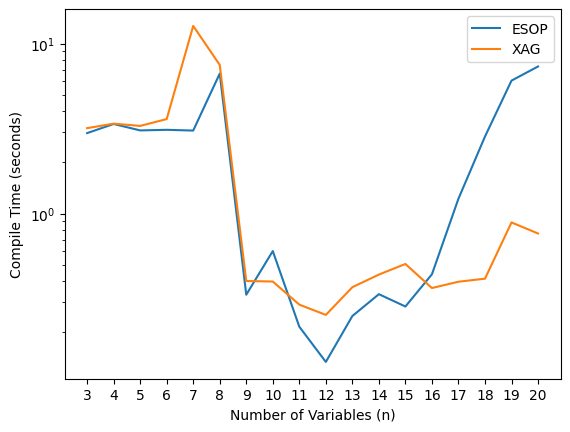

In [9]:
num_vars_data = range(3, 21)
data = average_timing_data(aggregated_data, "mean")
esop_mean_data = [data["CLASSICAL_FUNCTION"][str(n)] for n in num_vars_data]
xag_mean_data = [data["XAG"][str(n)] for n in num_vars_data]
plt.plot(num_vars_data, esop_mean_data, label='ESOP')
plt.plot(num_vars_data, xag_mean_data, label='XAG')
plt.xticks(num_vars_data)
plt.xlabel('Number of Variables (n)')
plt.ylabel('Compile Time (seconds)')
plt.yscale('log')
plt.legend()
plt.savefig('plots/timing_results_mean.png')
plt.show()

In [ ]:
num_vars_data = range(3, 9)
data = average_timing_data(aggregated_data, "median")
esop_median_data = [data["CLASSICAL_FUNCTION"][n] for n in num_vars_data]
xag_median_data = [data["XAG"][n] for n in num_vars_data]
plt.plot(num_vars_data, esop_median_data, label='ESOP')
plt.plot(num_vars_data, xag_median_data, label='XAG')
plt.xticks(num_vars_data)
plt.xlabel('Number of Variables (n)')
plt.ylabel('Compile Time (seconds)')
plt.yscale('log')
plt.title('')
plt.legend()
plt.savefig('plots/Clique_timing_results_median.png')
plt.show()